In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# global variables
N_SNAPS = 2 # number of pictures 
N_RUN = 100 # number of steps until a picture is taken
CELL_PROGRESS_CHECK = 24 # how often do we check if a given cell can divide
SIZE = 50
WINDOW_SIZE = 25
K_D = 1e-3  # chance of death
K_B = 1e-1 # chance of birth
K_ATTRACTIVE = 1
K_REPULSIVE = 50
ALPHA = 0.1
DELTA_T = 1e-2

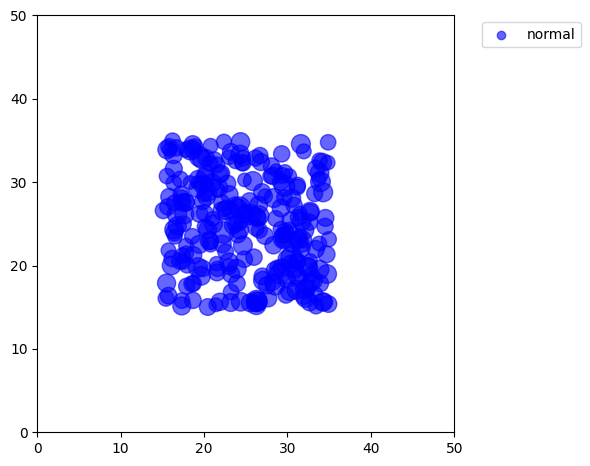

iteration 0


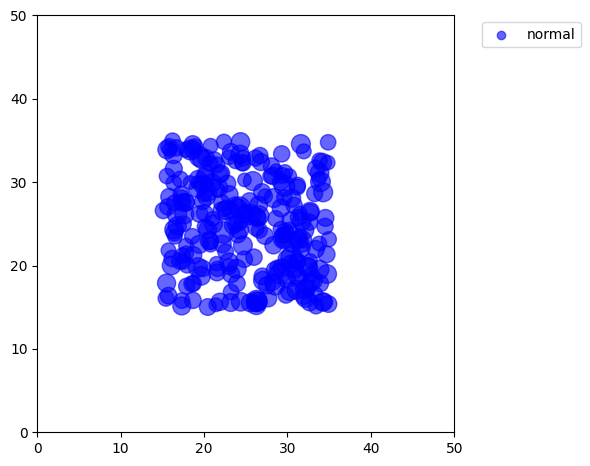

iteration 8


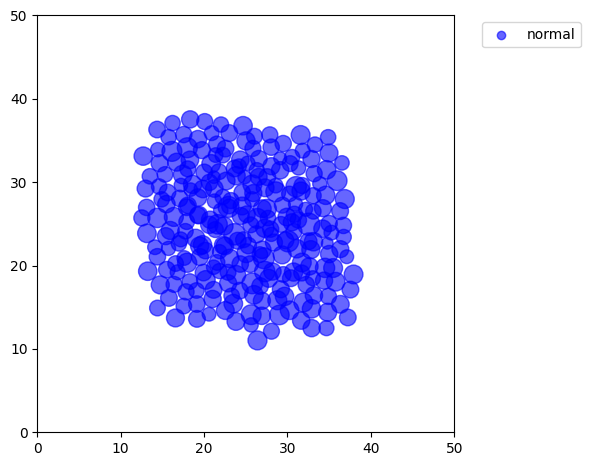

iteration 16


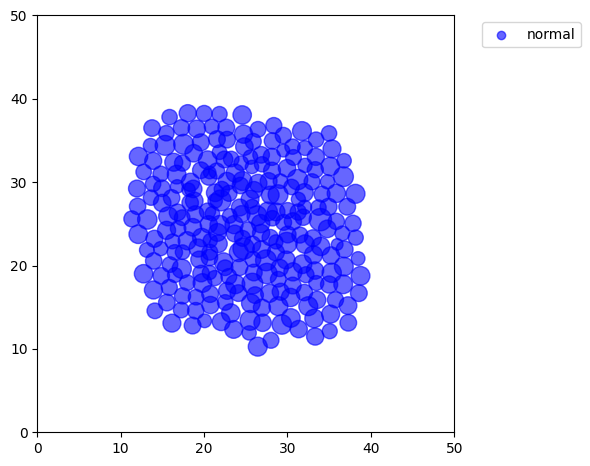

iteration 24


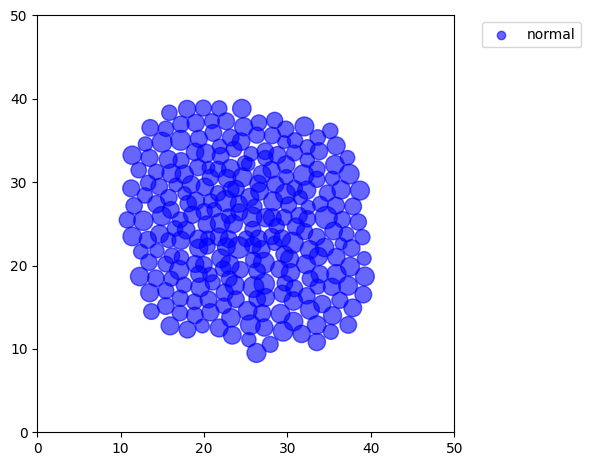

iteration 32


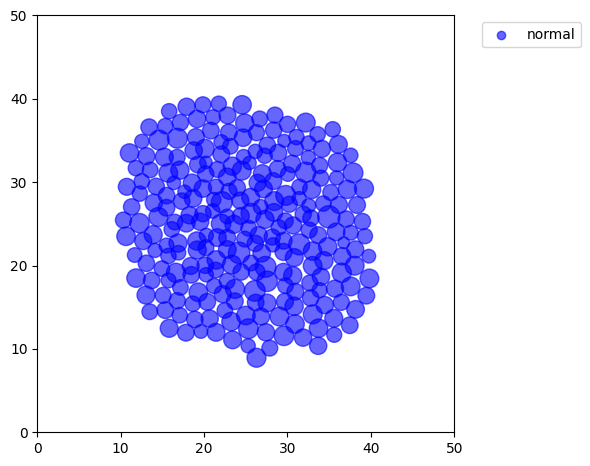

iteration 40


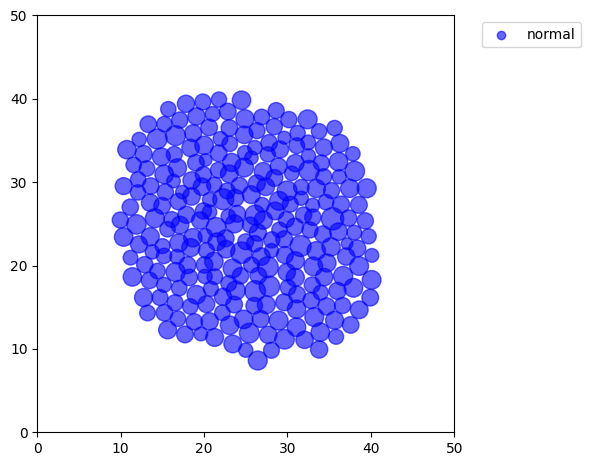

iteration 48


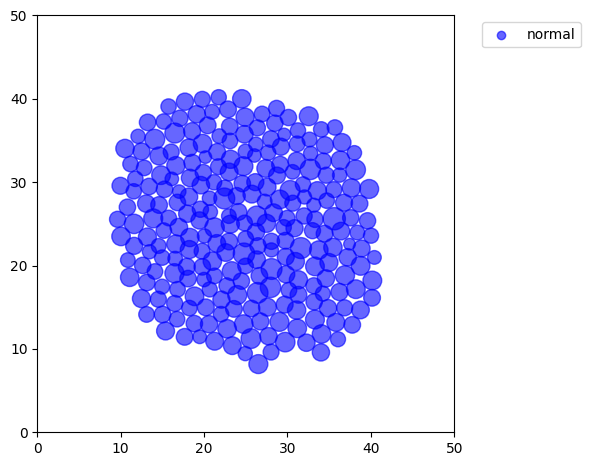

iteration 56


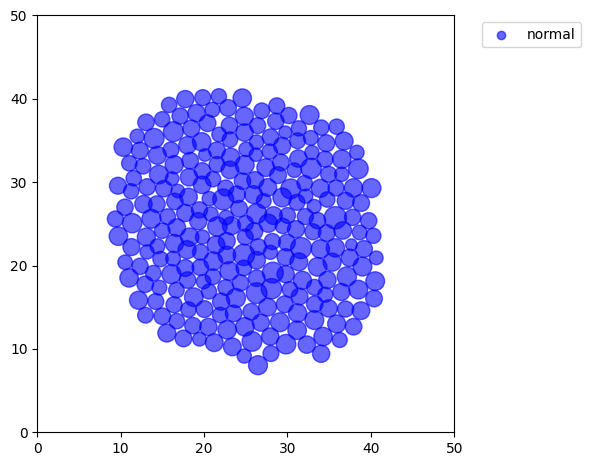

iteration 64


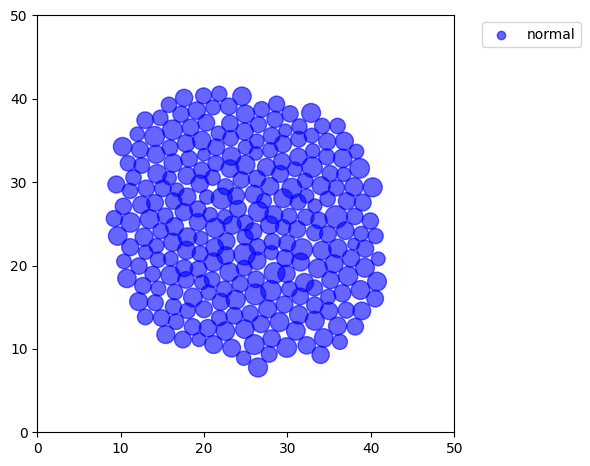

iteration 72


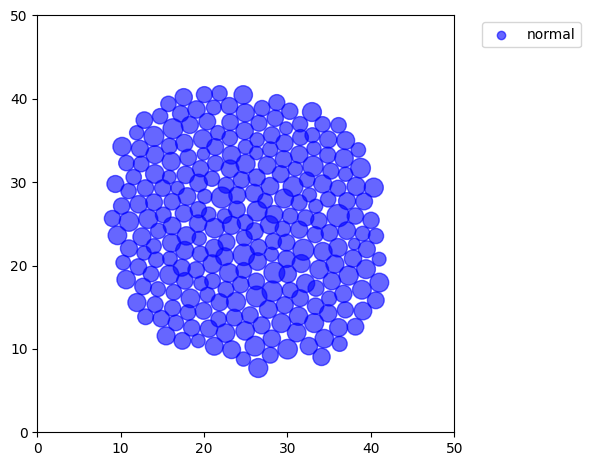

iteration 80


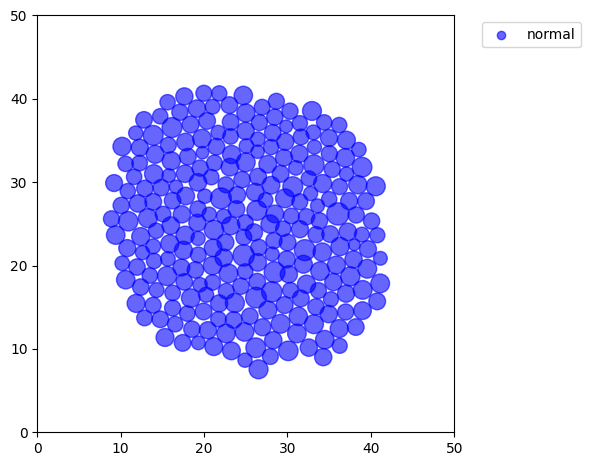

iteration 88


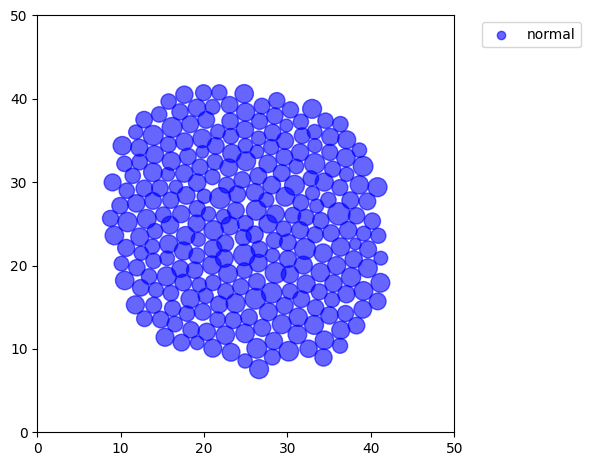

iteration 96


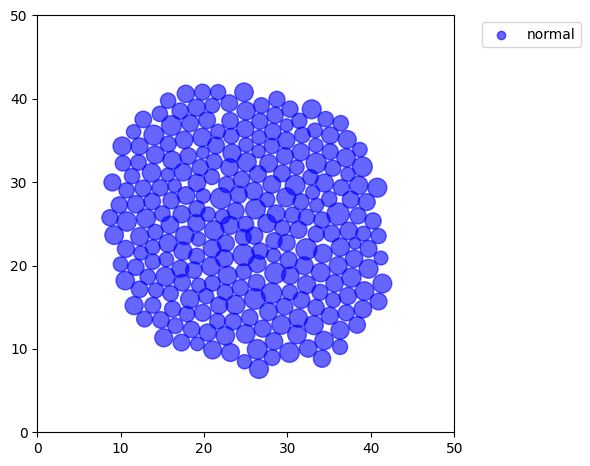

iteration 104


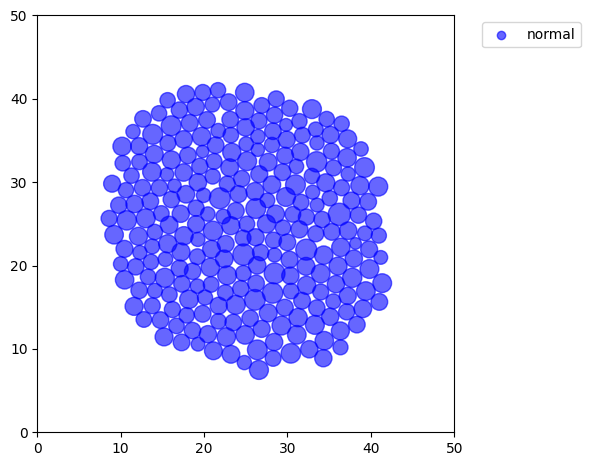

iteration 112


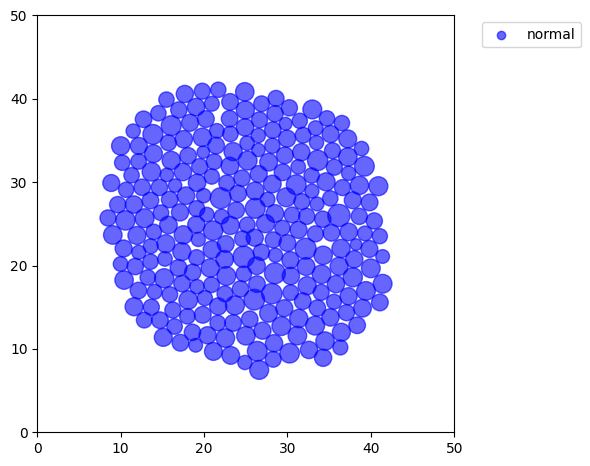

iteration 120


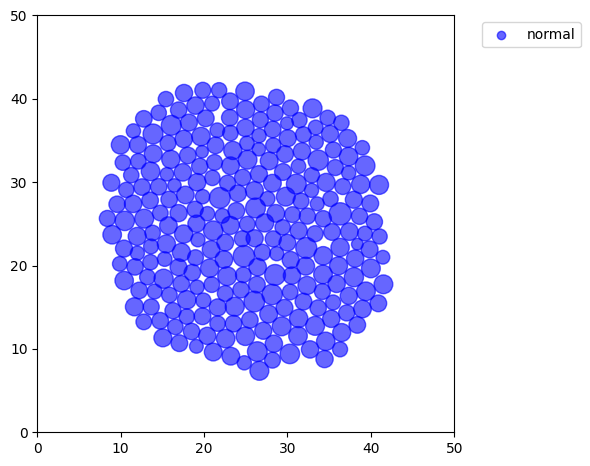

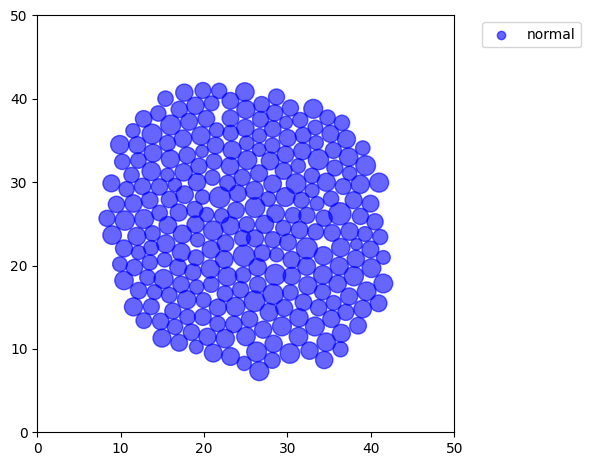

In [121]:
# NOTE
# do not add or remove particles in the movement stage, do it before or after
# not concurrently

class System():
    def __init__(self, particle_count, max_particles):
        # preallocate the numpy arrays
        self.max_particles = max_particles
        self.n = 0  # start with 0, we'll add particles via new_cell()
        self.pos = np.empty((max_particles, 2))
        self.R   = np.empty((max_particles, 1))
        self.type = np.empty((max_particles, 1), dtype="U10")
        self.k_d = np.empty((max_particles, 1))
        self.k_b = np.empty((max_particles, 1))
        self.t = np.empty((max_particles, 1))

        # add initial particles using new_cell()
        for _ in range(particle_count):
            pos = np.random.uniform(low=0.3*SIZE, high=0.7*SIZE, size=(2,))
            R = np.random.normal(1.0, 1e-1, size=(1,))
            type_ = "normal"
            k_d = K_D
            k_b = K_B
            self.new_cell(pos, R, type_, k_d, k_b)

    def new_cell(self, pos, R, type_, k_d, k_b):
        if self.n >= self.max_particles:
            raise ValueError("Maximum particle capacity reached!")

        i = self.n
        self.pos[i] = pos
        self.R[i] = R
        self.type[i] = type_
        self.k_d[i] = k_d
        self.k_b[i] = k_b
        self.t[i] = 0
        self.n += 1

    def remove_particle(self, i):
        last = self.n - 1  # index of last active particle
        if i != last:
            # Swap particle i with the last active particle
            self.pos[i] = self.pos[last]
            self.R[i]   = self.R[last]
            self.type[i] = self.type[last]
            self.k_d[i] = self.k_d[last]
            self.k_b[i] = self.k_b[last]
            self.t[i] = self.t[last]
        self.n -= 1

    def print_status(self):
        print(f"positions:\n {self.pos[:self.n]}\n")
        print(f"radii:\n {self.R[:self.n]}\n")
        print(f"types:\n {self.type[:self.n]}\n")

    def find_neighbours(self):
        # returns a list of neighbor indices for each particle
        neighbours = []

        for i in range(system.n):
            # compute all the distances
            delta_pos = system.pos[:system.n] - system.pos[i]

            # periodic boundary condition, maintaining the correct sign
            delta_pos -= SIZE * np.round(delta_pos / SIZE)

            # keep only the particles within a given threshold
            mask = (np.abs(delta_pos[:,0]) <= WINDOW_SIZE) & (np.abs(delta_pos[:,1]) <= WINDOW_SIZE)

            mask[i] = False
            vectors = delta_pos[mask]
            radii = self.R[:self.n][mask]

            neighbours.append(zip(vectors, radii))

        return neighbours
    
    def update_pos(self):
        neighbour_list = self.find_neighbours()
        for i in range(system.n):
            # print(f"pos of particle {i}:\ninitial:\t{self.pos[i]}")
            F = np.zeros((2))
            for vec, radius in neighbour_list[i]:
                distance = np.linalg.norm(vec)
                sum_of_radii = self.R[i] + radius

                vec_normalized = vec / distance
                if distance < sum_of_radii:
                    # repulsive
                    F -= K_REPULSIVE * (sum_of_radii - distance) * vec_normalized
                elif distance <= 1.1*sum_of_radii:
                    F += K_ATTRACTIVE * vec_normalized

            # now that we have collected all the forces, we can
            # update the position of our particle
            eta = np.random.normal(0, 1.0, size=(2))  # 2D Gaussian
            self.pos[i] += F * DELTA_T + np.sqrt(ALPHA * DELTA_T) * eta
            # print(f"F = {F}")
            # print(f"updated:\t{self.pos[i]}")
            

    def print_neighbours(self, neighbours_list):
        """
        Prints each particle's position and its neighbor displacement vectors.
        neighbours_list: output of self.find_neighbours()
        """
        for i in range(self.n):
            print(f"Particle {i}: position = {self.pos[i]}")
            print(f"  Neighbors (dx, dy, R):")
            for vec, radius in neighbours_list[i]:
                print(f"\t{vec}, {radius}")
            print()  # blank line for readability


    def plot_system(self):
        fig, ax = plt.subplots(figsize=(6,6))
        type_colors = {"normal": "blue", "cancerous": "red"}  # add more if needed
        legend_added = set()

        for i in range(self.n):
            particle_type = self.type[i,0]
            color = type_colors.get(particle_type, "black")
            circle = plt.Circle(
                (self.pos[i,0], self.pos[i,1]),
                radius=self.R[i,0],
                color=color,
                alpha=0.6
            )
            ax.add_patch(circle)

            if particle_type not in legend_added:
                ax.scatter([], [], color=color, alpha=0.6, label=particle_type)
                legend_added.add(particle_type)

        ax.set_xlim(0, SIZE)
        ax.set_ylim(0, SIZE)
        ax.set_aspect('equal')
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()

system = System(256, 1024)
# system.new_cell((10,10), 3, "cancerous",0,0)
system.plot_system()
for i in range(124):
    if i % 8 == 0: 
        print(f"iteration {i}")
        system.plot_system()
    system.update_pos()

system.plot_system()
